# Motif tracking over time

Mouse 720762. Algorithm in `src/motif_tracking.py`, with no fixed epochs or bins:

1. Band envelopes at 1 Hz (report bands), z-scored once over the recording.
2. **Sliding baseline and spread** per band (5-min rolling mean and SD), cut at known event boundaries (isoflurane on,
   end of induction, stimulus block edges). **Residual** = (z − baseline) / spread: the fast part.
3. **Motif detection in sliding windows** (5 min, every 1 min) on the residual (Mishler, signs); candidates with
   permutation p ≤ 0.05 kept.
4. **Tracks:** candidates in consecutive windows linked when |cos| ≥ 0.8 (gaps of 1 window allowed). Tracks living
   ≥ 3 windows form the **library**, merged when their mean directions match (|cos| ≥ 0.9).
5. **Per library motif over time:**
   - per second: expression, baseline position, rolling spread;
   - per window: presence and p, pole occupancy (+ / 0 / −), bimodality (dip test against 19 phase surrogates,
     p < 0.05), direction.

**Direction** is measured two ways. The *detected angle* is between the motif and the closest window detection
(Mishler-native, only when something was detected). The *local angle* is between the motif and the closest
eigen-direction of the window's correlation matrix, with a **noise floor** (the same estimate made separately on the two
halves of the window, alternating 30-s blocks). The **held-out gain** asks whether a direction re-estimated on one
half explains the other half better than the fixed motif does. Positive means the motif has really moved; around zero
or negative means a fixed direction is as good.

Section 6 runs the same thing on four signals, to show it scales.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import motif_tracking as mt
from src import session_data as sd
from src.channel_sweep import list_signals
from src.state_motifs import band_labels
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
MOUSE = "720762"
OUT = REPO / "data" / "out" / "2026-11-10_motif_tracking"
STORE = REPO / "data" / "processed" / "motif_tracking" / MOUSE
OUT.mkdir(parents=True, exist_ok=True); STORE.mkdir(parents=True, exist_ok=True)
names = band_labels()
cfg = mt.TrackConfig()

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")

info, (run_t, run), (pupil_t, pupil) = mt.behaviour(NWB)
res, sig = mt.track_signal(NWB, "lfp_PL5", ("lfp", "probeF", "PL5"), cfg)
mt.save(res, STORE / "lfp_PL5.pkl")
K = len(res.library)
MCOL = plt.get_cmap("tab10")
print(f"{len(res.centres)} windows, {len(res.candidates)} candidates (p ≤ {cfg.alpha}), {len(res.tracks)} tracks, {K} library motifs")
pd.DataFrame([{"motif": f"M{i + 1}", "windows alive": m.life, "tracks merged": len(m.tracks), "broadband": m.broadband}
              for i, m in enumerate(res.library)]).set_index("motif")

114 windows, 191 candidates (p ≤ 0.05), 53 tracks, 9 library motifs


,windows alive,tracks merged,broadband
motif,,,
M1,89,2,True
M2,25,4,False
M3,4,1,False
M4,4,1,False
M5,4,1,False
M6,4,1,False
M7,3,1,False
M8,3,1,False
M9,3,1,False


## 1. Library and tracks

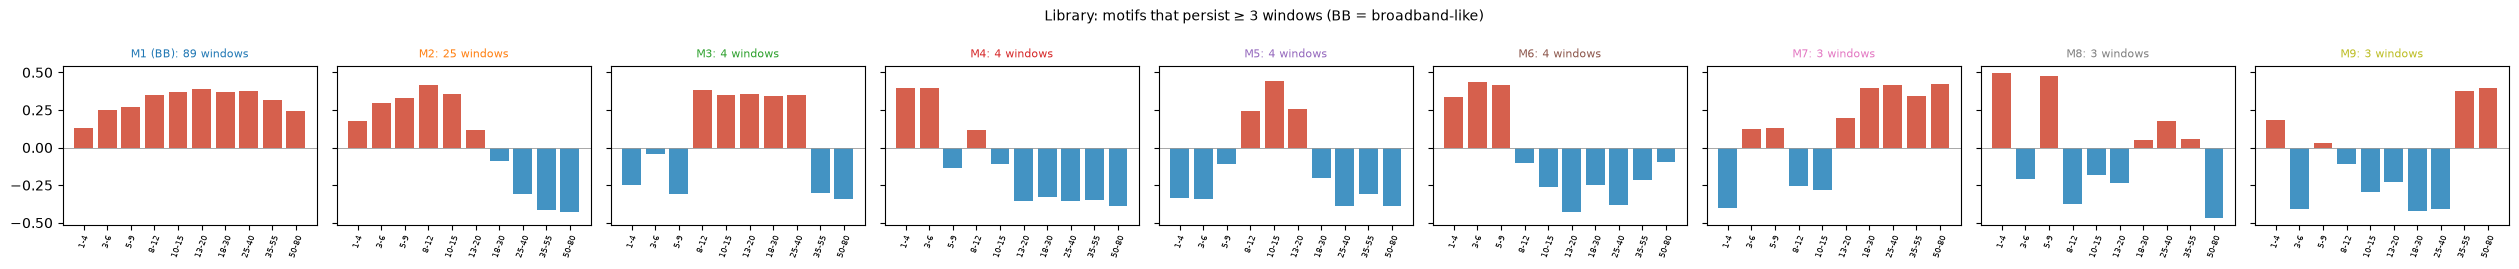

In [2]:
fig, axes = plt.subplots(1, K, figsize=(2.8 * K, 2.7), sharey=True, squeeze=False)
for i, (ax, m) in enumerate(zip(axes[0], res.library)):
    u = m.template
    ax.bar(range(10), u, color=np.where(u >= 0, "#d6604d", "#4393c3")); ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xticks(range(10), names, rotation=70, fontsize=6)
    ax.set_title(f"M{i + 1}{' (BB)' if m.broadband else ''}: {m.life} windows", fontsize=8, color=MCOL(i))
fig.suptitle("Library: motifs that persist ≥ 3 windows (BB = broadband-like)", fontsize=10)
fig.tight_layout(); save(fig, "1_library"); plt.show()

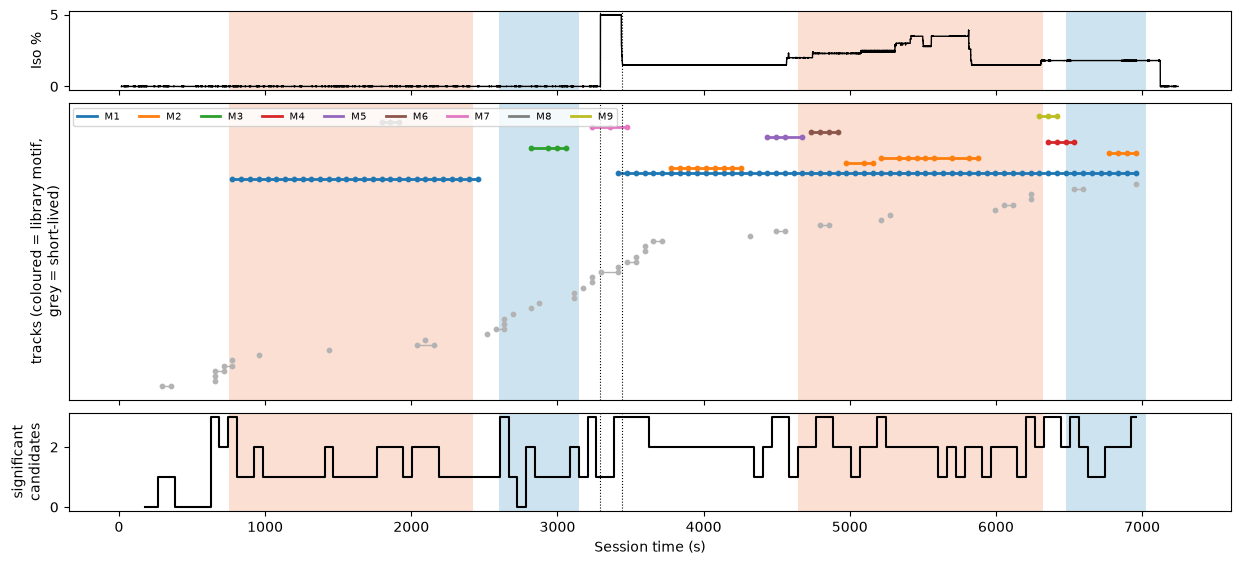

In [3]:
def events(ax, labels=False):
    for _, a, b in info.stim_blocks: ax.axvspan(a, b, color="#f4a582", alpha=0.35, lw=0)
    for _, a, b in info.visual_blocks: ax.axvspan(a, b, color="#92c5de", alpha=0.45, lw=0)
    for x in (info.iso_on, info.induction_end): ax.axvline(x, color="k", ls=":", lw=0.8)

fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(3, 1, height_ratios=[0.8, 3, 1], hspace=0.08)
ax0 = fig.add_subplot(gs[0]); ax0.plot(info.iso_t, info.iso_level, "k", lw=1); ax0.set_ylabel("Iso %"); events(ax0)
ax1 = fig.add_subplot(gs[1], sharex=ax0)
tr = res.tracks.sort_values(["motif", "first"])
for row, (_, r) in enumerate(tr.iterrows()):
    c = res.candidates[res.candidates.track == r.track]
    col = MCOL(int(r.motif)) if r.motif >= 0 else "0.7"
    ax1.plot(c.centre, np.full(len(c), row), "-", color=col, lw=2 if r.motif >= 0 else 1)
    ax1.scatter(c.centre, np.full(len(c), row), s=10, color=col, zorder=3)
ax1.set_ylabel("tracks (coloured = library motif,\ngrey = short-lived)"); ax1.set_yticks([]); events(ax1)
for i in range(K):
    ax1.plot([], [], color=MCOL(i), lw=2, label=f"M{i + 1}")
ax1.legend(fontsize=7, ncol=K, loc="upper left")
ax2 = fig.add_subplot(gs[2], sharex=ax0)
ax2.step(res.centres, res.n_candidates, where="mid", color="k"); ax2.set_ylabel("significant\ncandidates"); events(ax2)
ax2.set_xlabel("Session time (s)")
for a in (ax0, ax1): plt.setp(a.get_xticklabels(), visible=False)
save(fig, "1_tracks"); plt.show()

## 2. Each motif over time

Per motif, top to bottom:
- isoflurane and stimulus blocks;
- running speed;
- pupil width;
- **baseline position** (global z, the slow part);
- **expression** (residual units; 30-s mean) with ±1 rolling SD (the spread);
- **pole occupancy** per window (share of seconds above +0.5 / within ±0.5 / below −0.5);
- **presence** (dot when detected in that window; size grows as p falls) and **bimodality** (red tick when the window's
  expression is bimodal beyond surrogates);
- **direction**: detected angle (dots), local angle (line) and its noise floor (grey band).

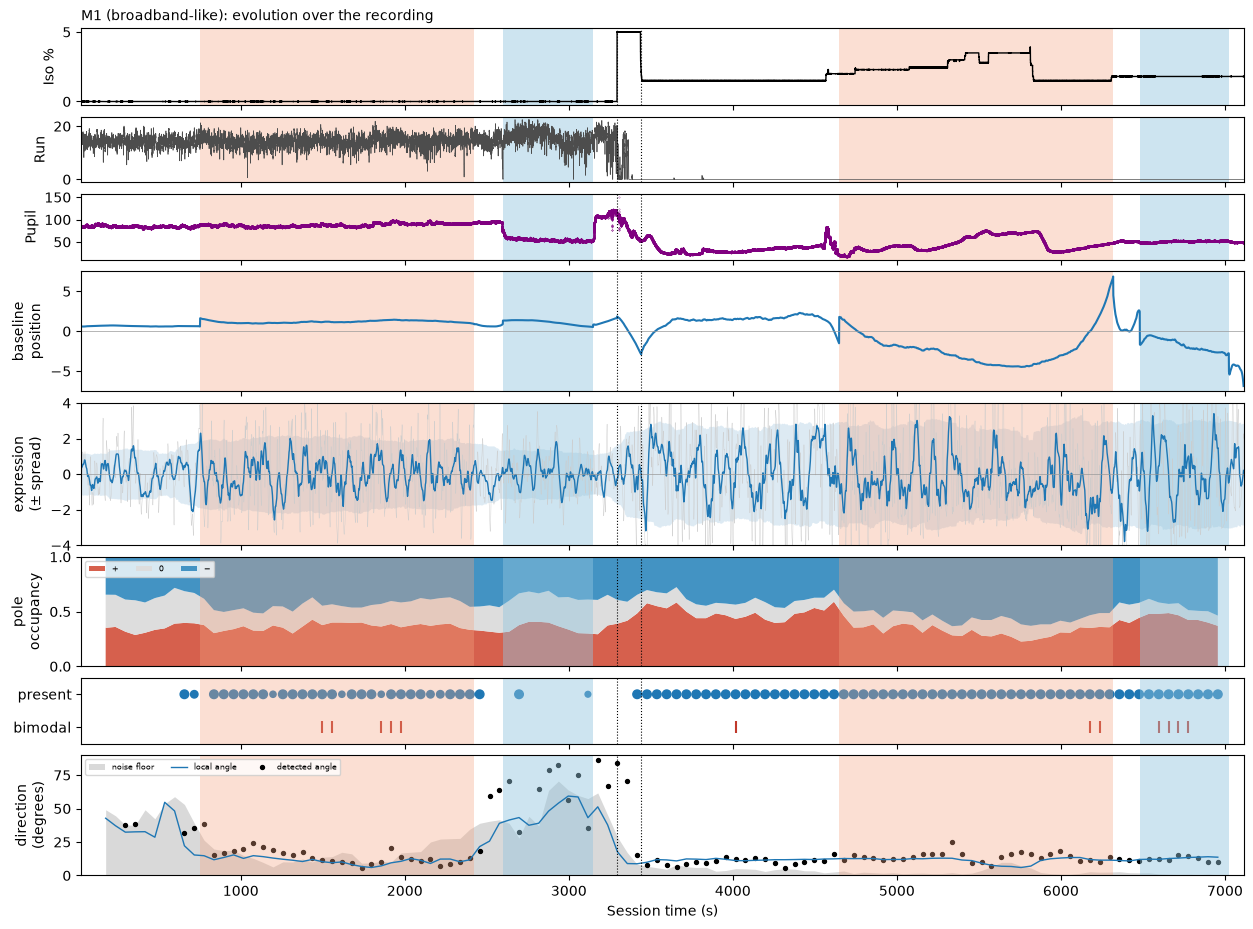

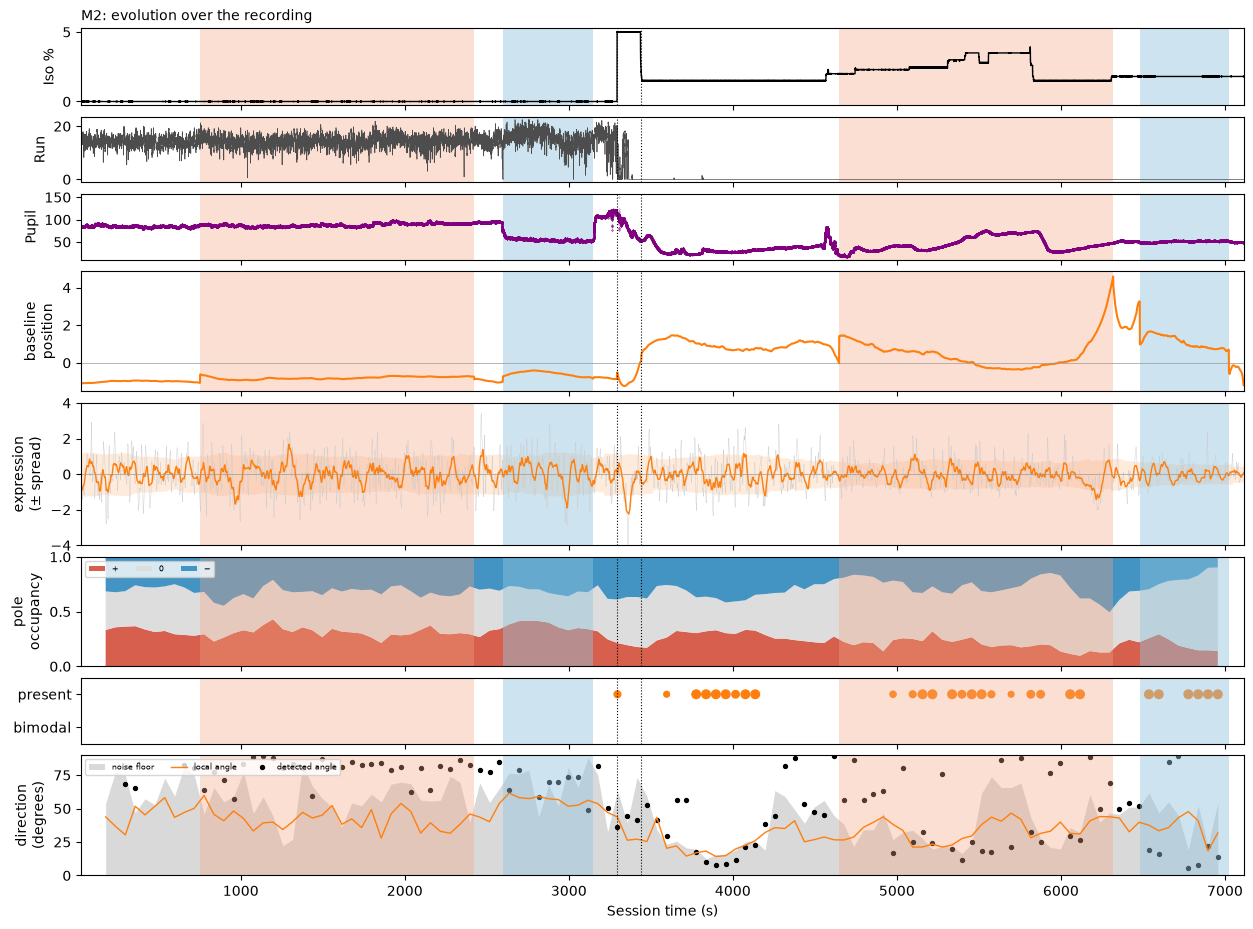

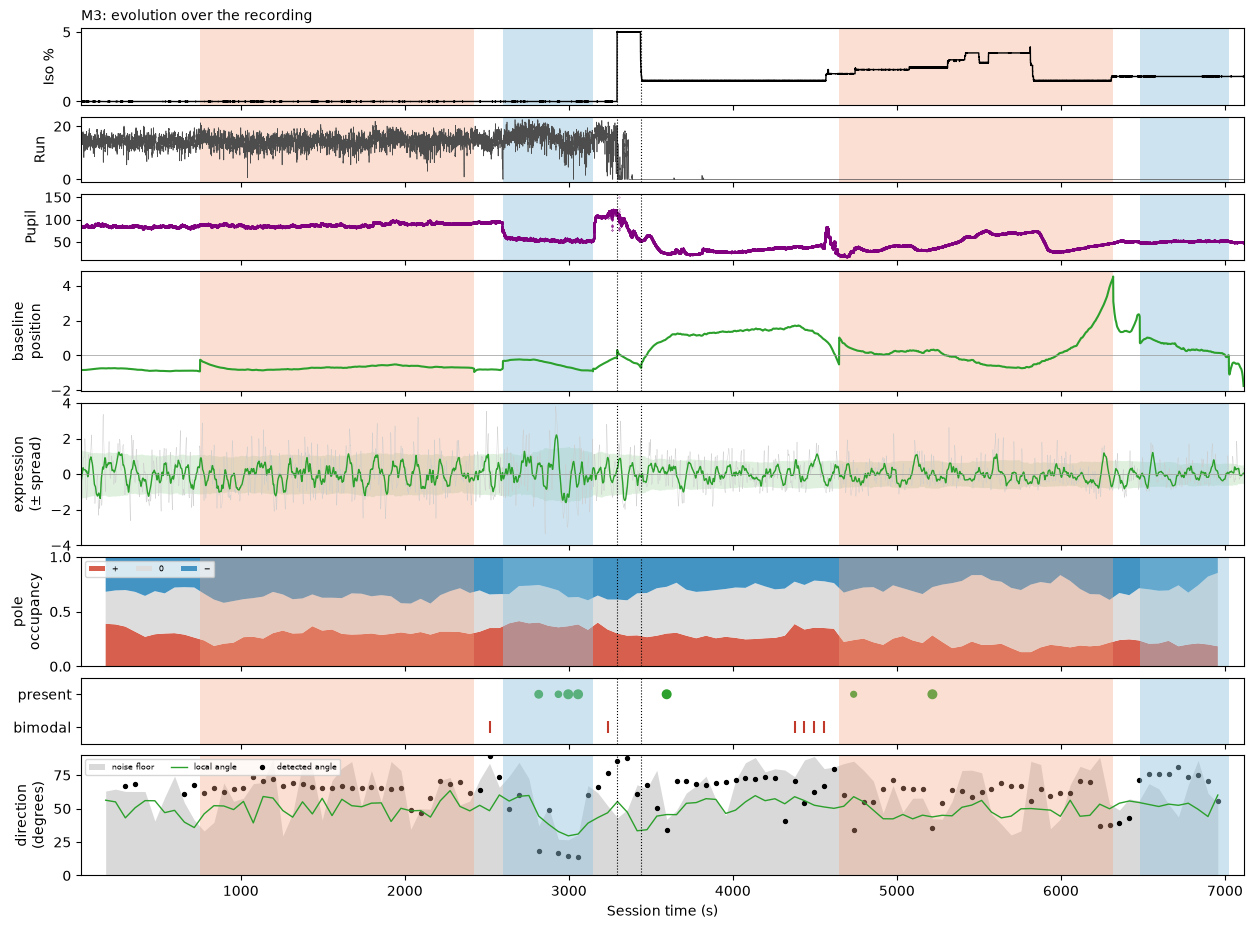

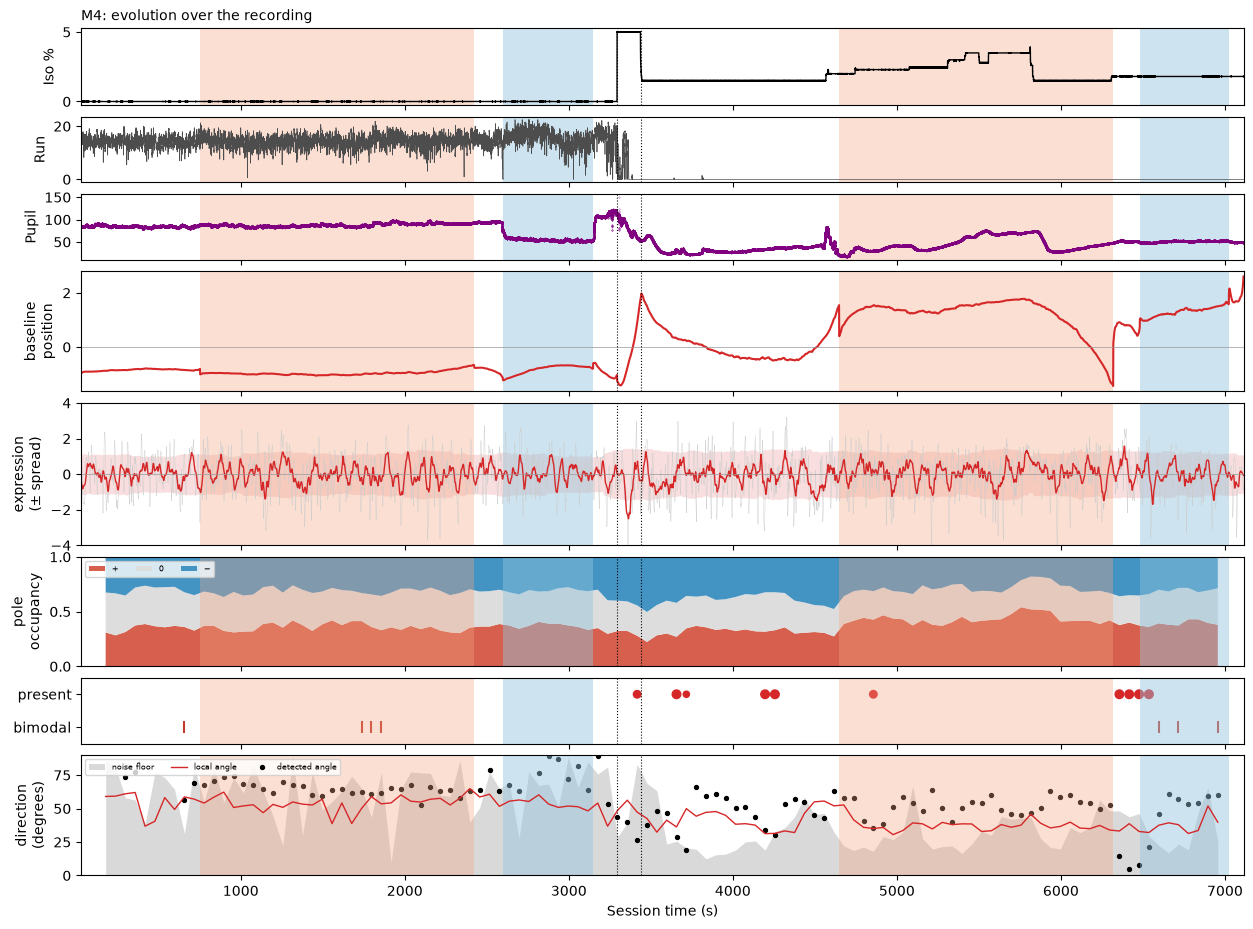

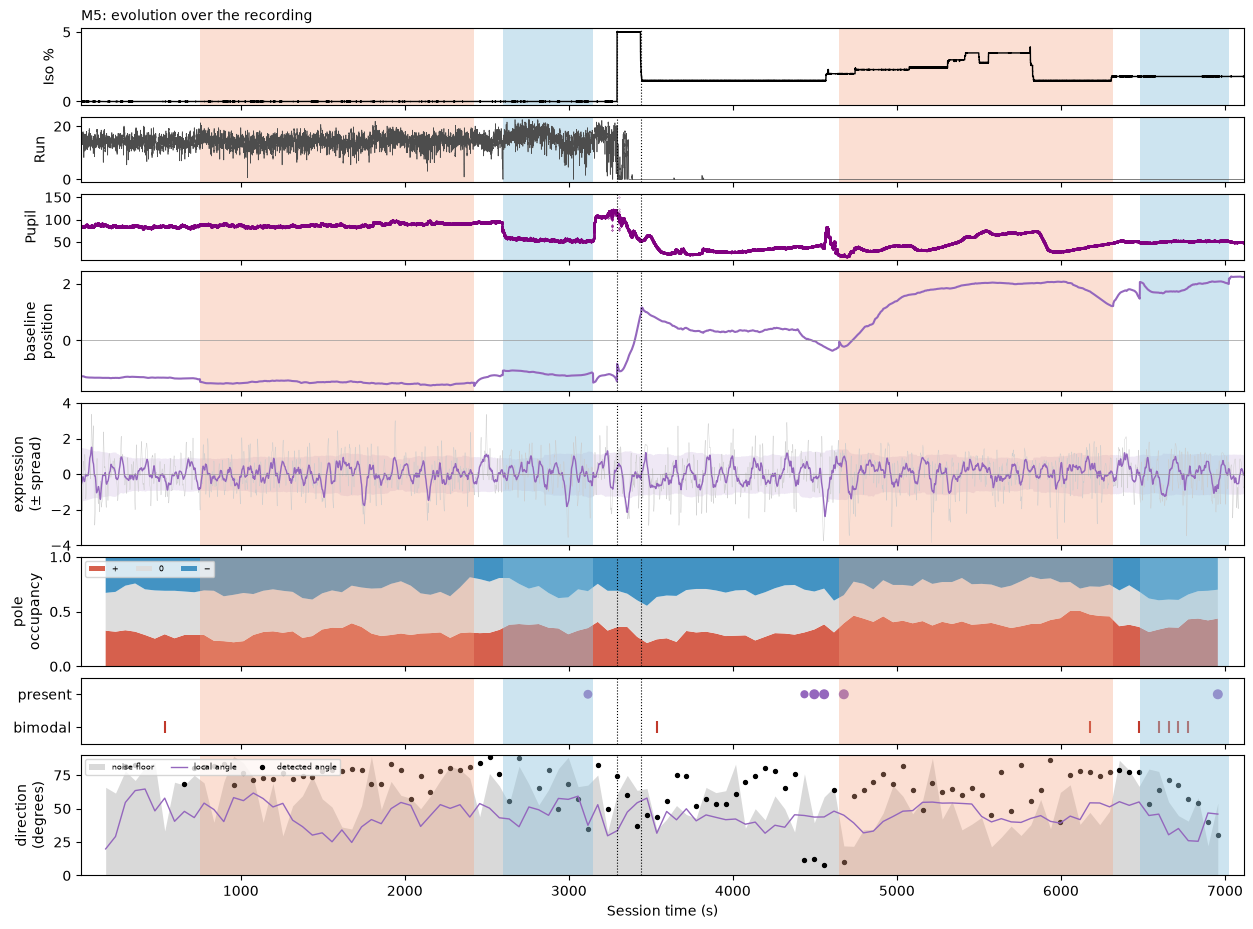

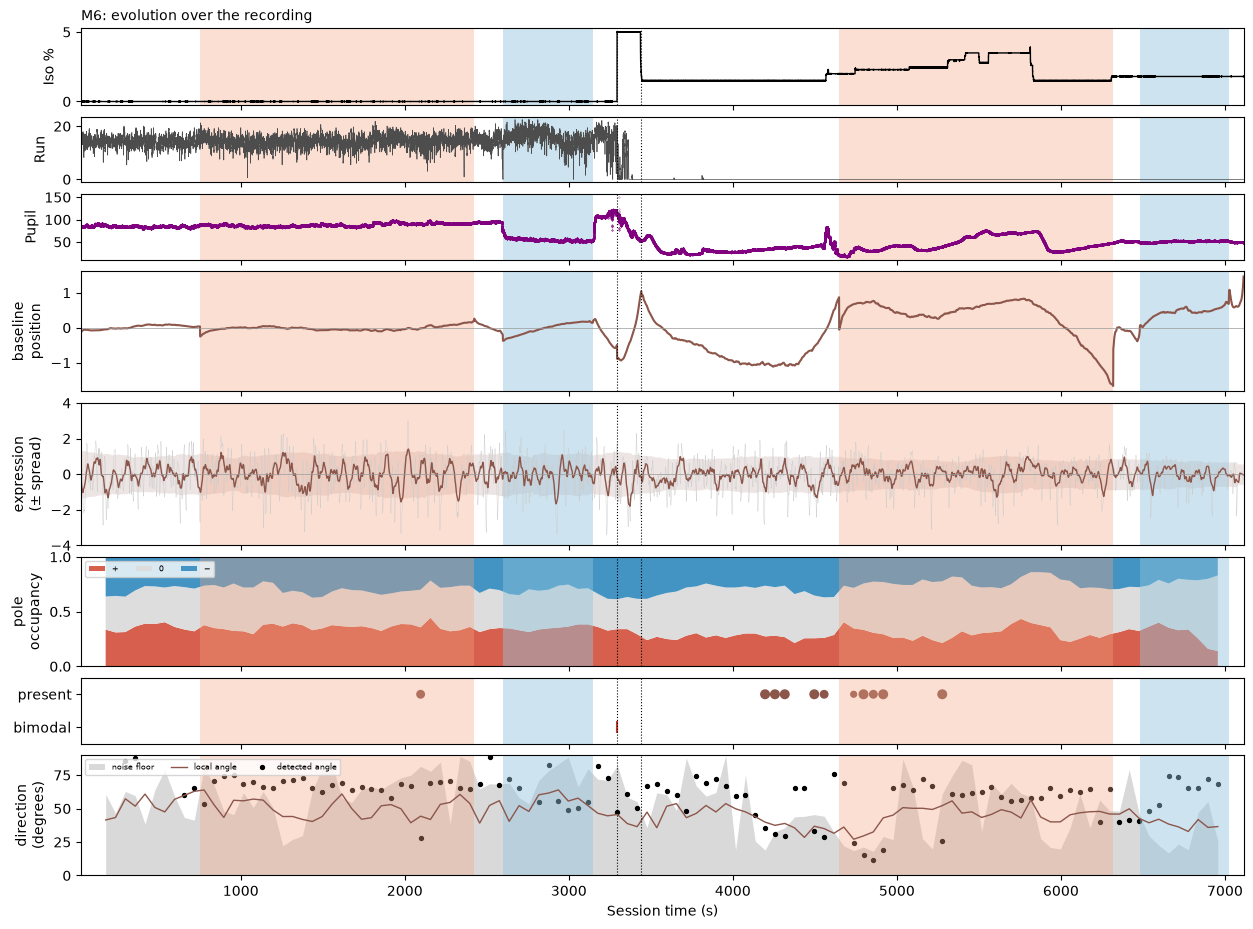

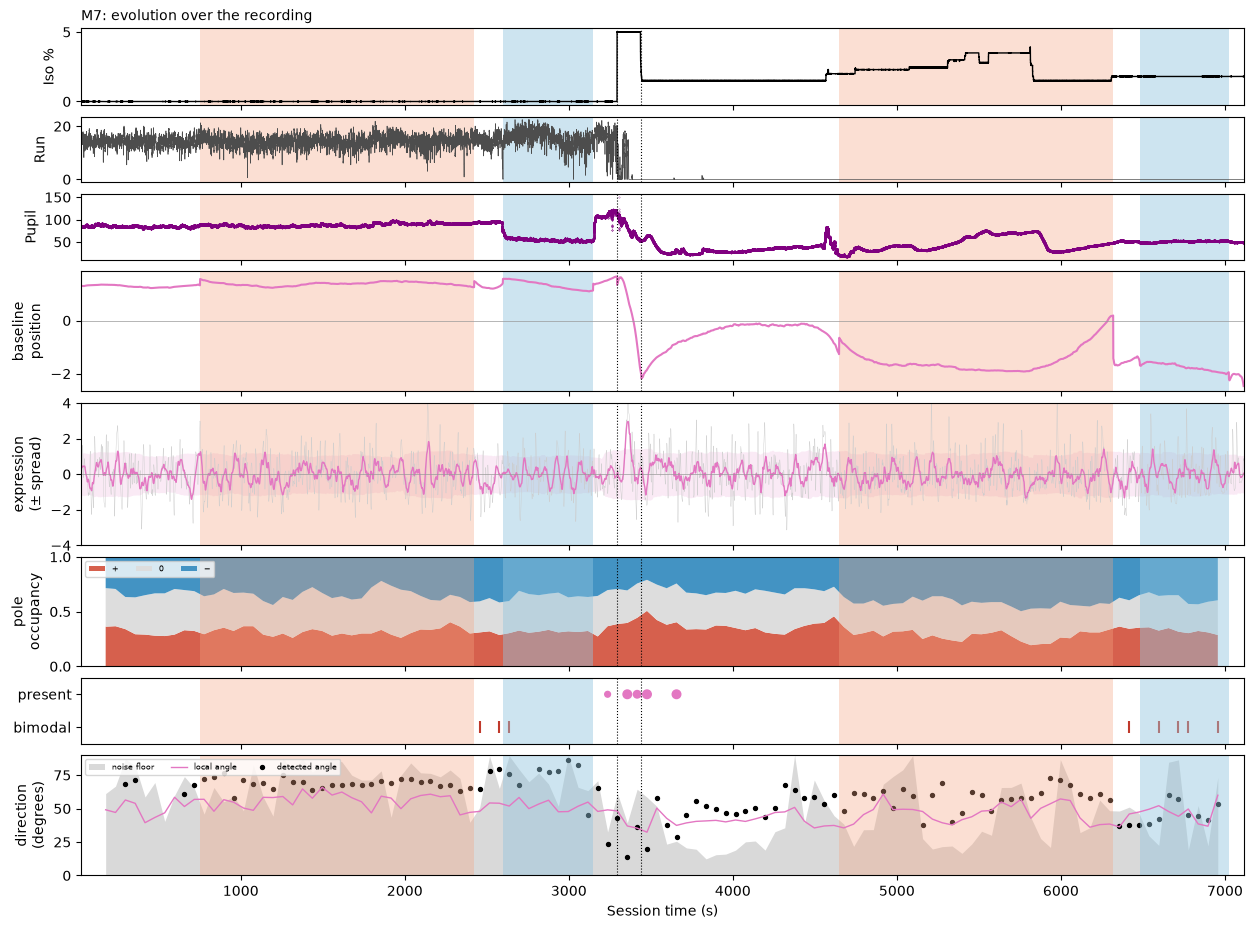

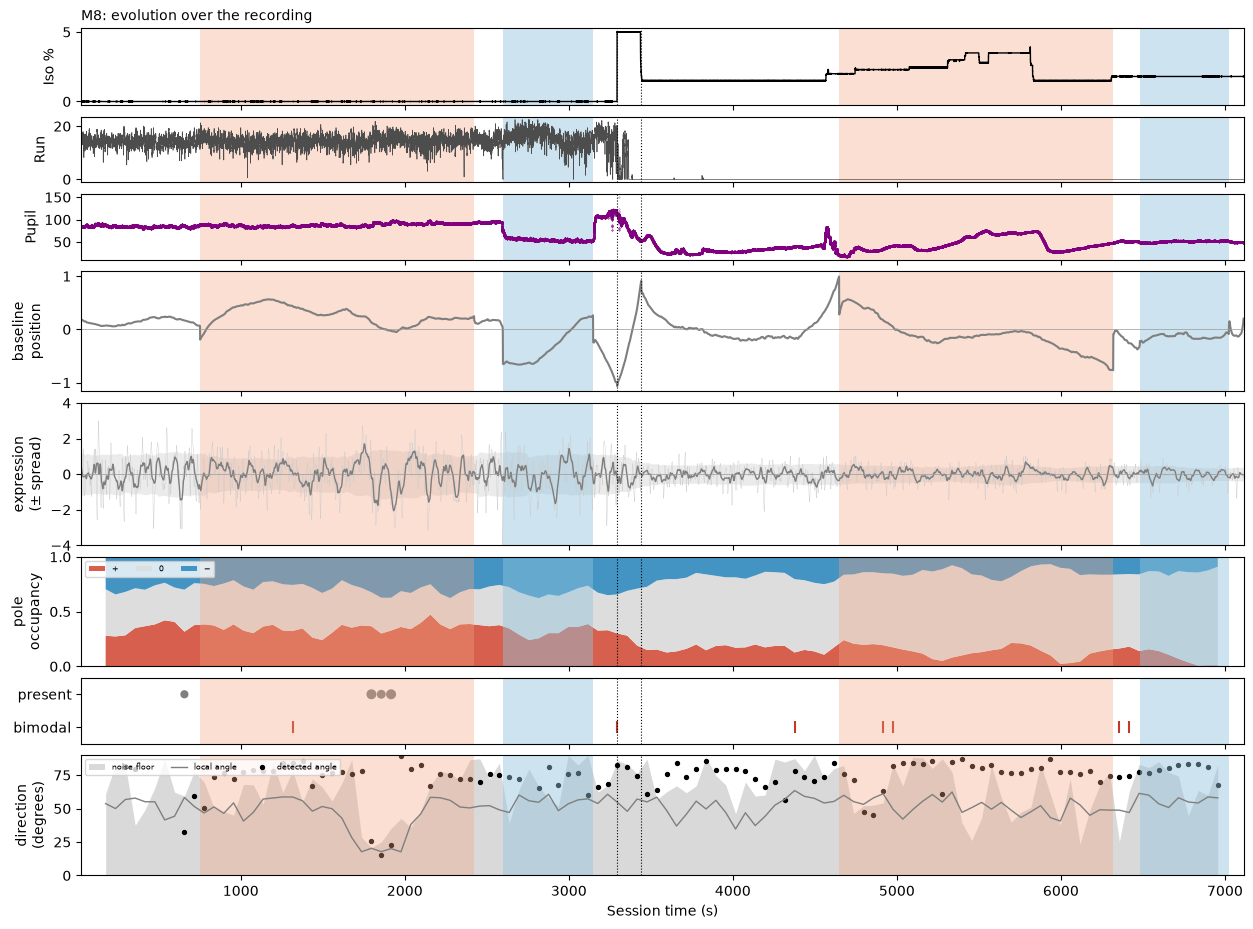

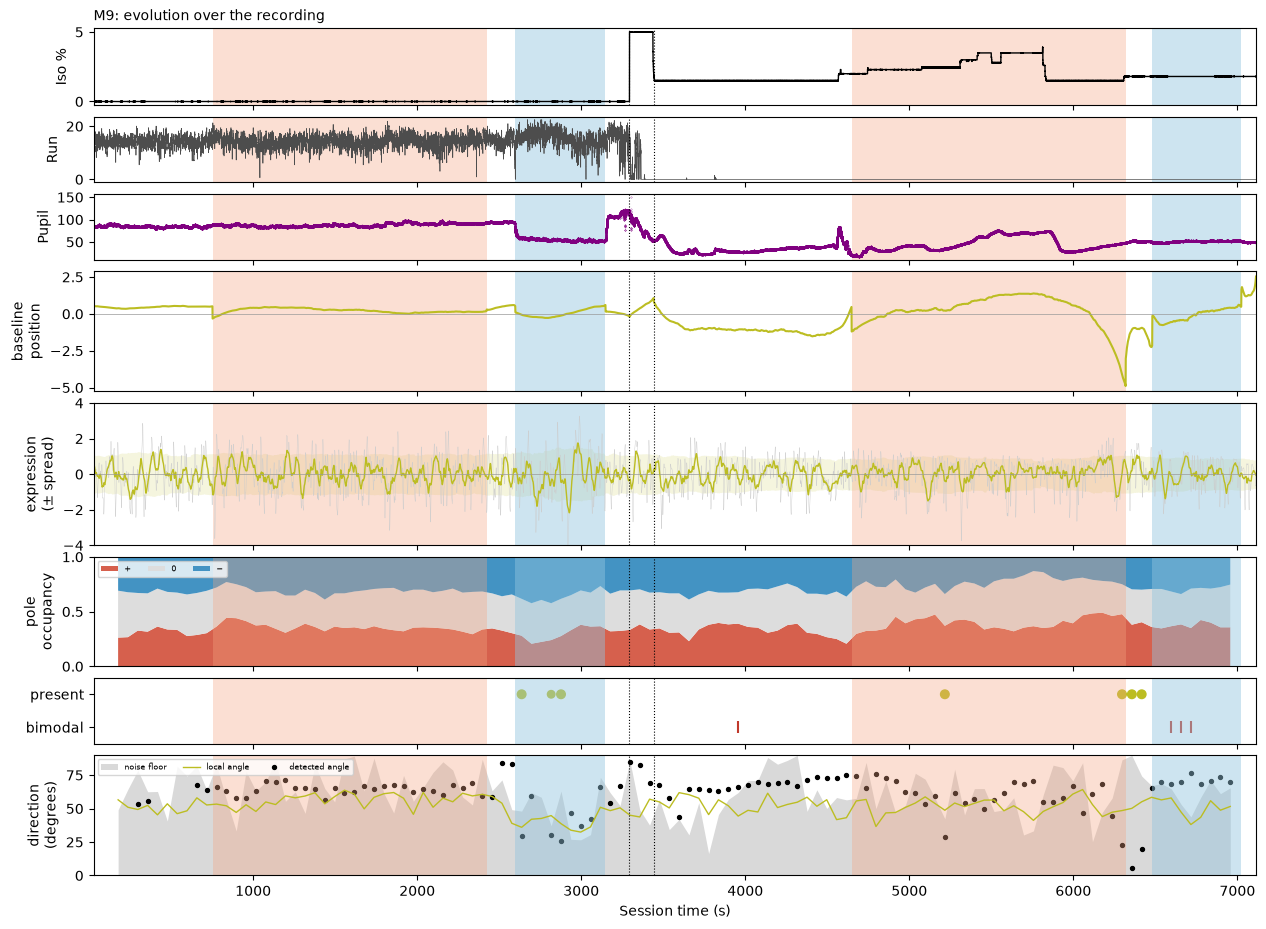

In [4]:
ws = res.window_stats
sec = res.second

def motif_figure(mi):
    w = ws[ws.motif == mi].sort_values("centre")
    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(8, 1, height_ratios=[0.7, 0.6, 0.6, 1.1, 1.3, 1.0, 0.6, 1.1], hspace=0.12)
    axs = [fig.add_subplot(gs[0])]
    axs += [fig.add_subplot(gs[i], sharex=axs[0]) for i in range(1, 8)]
    axs[0].plot(info.iso_t, info.iso_level, "k", lw=1); axs[0].set_ylabel("Iso %")
    axs[1].plot(run_t, smooth(run, 100), color="0.3", lw=0.5); axs[1].set_ylabel("Run")
    axs[2].plot(pupil_t, pupil, ".", ms=0.4, color="purple"); axs[2].set_ylabel("Pupil")
    axs[3].plot(sec.t, sec[f"base_M{mi + 1}"], color=MCOL(mi), lw=1.5); axs[3].axhline(0, color="0.6", lw=0.5)
    axs[3].set_ylabel("baseline\nposition")
    e30 = pd.Series(sec[f"expr_M{mi + 1}"].to_numpy()).rolling(30, center=True, min_periods=10).mean()
    sp = sec[f"spread_M{mi + 1}"]
    axs[4].fill_between(sec.t, -sp, sp, color=MCOL(mi), alpha=0.15, lw=0)
    axs[4].plot(sec.t, smooth(np.nan_to_num(sec[f"expr_M{mi + 1}"].to_numpy()), 5), color="0.8", lw=0.3)
    axs[4].plot(sec.t, e30, color=MCOL(mi), lw=1); axs[4].axhline(0, color="0.6", lw=0.5)
    axs[4].set_ylim(-4, 4); axs[4].set_ylabel("expression\n(± spread)")
    axs[5].stackplot(w.centre, w.p_plus, w.p_zero, w.p_minus, colors=["#d6604d", "#dddddd", "#4393c3"], labels=["+", "0", "−"])
    axs[5].set_ylim(0, 1); axs[5].set_ylabel("pole\noccupancy"); axs[5].legend(fontsize=6, loc="upper left", ncol=3)
    pr = w[w.present]
    axs[6].scatter(pr.centre, np.ones(len(pr)), s=8 + 30 * (-np.log10(pr.best_p) - 1), color=MCOL(mi))
    bm = w[w.bimodal]
    axs[6].scatter(bm.centre, np.zeros(len(bm)), marker="|", s=80, color="#c0392b")
    axs[6].set_yticks([0, 1], ["bimodal", "present"]); axs[6].set_ylim(-0.5, 1.5)
    axs[7].fill_between(w.centre, 0, w.angle_noise, color="0.85", lw=0, label="noise floor")
    axs[7].plot(w.centre, w.angle_local, color=MCOL(mi), lw=1, label="local angle")
    axs[7].scatter(w.centre, w.angle_detected, s=8, color="k", label="detected angle")
    axs[7].set_ylim(0, 90); axs[7].set_ylabel("direction\n(degrees)"); axs[7].legend(fontsize=6, ncol=3, loc="upper left")
    axs[7].set_xlabel("Session time (s)")
    for a in axs:
        events(a)
    for a in axs[:-1]:
        plt.setp(a.get_xticklabels(), visible=False)
    axs[0].set_xlim(sec.t.iloc[0], sec.t.iloc[-1])
    axs[0].set_title(f"M{mi + 1}{' (broadband-like)' if res.library[mi].broadband else ''}: evolution over the recording", loc="left", fontsize=10)
    save(fig, f"2_motif_M{mi + 1}"); plt.show()

for mi in range(K):
    motif_figure(mi)

## 3. Does the motif direction move? (static vs moving)

Per motif, over windows where it carries more variance than a random direction (variance along it > 1.5, where the
direction is identifiable):
- median local angle vs median noise floor;
- share of windows where the local angle exceeds the noise floor;
- median held-out gain of a locally re-estimated direction over the fixed one, as a share of the fixed one's variance.

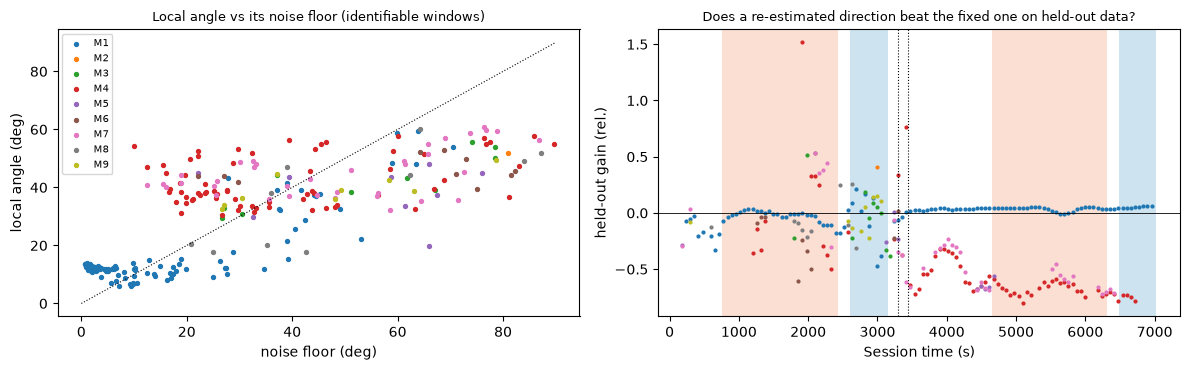

,windows used,median detected angle,median local angle,median noise floor,share angle > noise,median held-out gain (rel.),share bimodal windows,share windows present
motif,,,,,,,,
M1,110,13.38,12.20,6.73,0.60,0.03,0.11,0.81
M2,1,63.24,51.73,80.85,0.00,0.41,0.00,0.25
M3,10,65.52,41.17,56.52,0.40,-0.02,0.05,0.06
M4,68,58.36,38.66,31.20,0.60,-0.62,0.06,0.09
M5,9,69.58,43.64,61.35,0.22,-0.56,0.07,0.05
M6,10,64.98,44.46,69.96,0.30,-0.16,0.01,0.10
M7,36,60.86,42.53,48.29,0.39,-0.47,0.07,0.04
M8,10,76.76,41.17,40.79,0.20,-0.11,0.06,0.04
M9,9,65.03,38.75,48.10,0.44,-0.07,0.04,0.06


In [5]:
rows = []
for mi in range(K):
    w = ws[(ws.motif == mi) & (ws.var_along > 1.5)]
    rows.append({"motif": f"M{mi + 1}", "windows used": len(w),
                 "median detected angle": ws[(ws.motif == mi)].angle_detected.median(),
                 "median local angle": w.angle_local.median(), "median noise floor": w.angle_noise.median(),
                 "share angle > noise": (w.angle_local > w.angle_noise).mean() if len(w) else np.nan,
                 "median held-out gain (rel.)": w.heldout_gain_rel.median(),
                 "share bimodal windows": ws[ws.motif == mi].bimodal.mean(), "share windows present": ws[ws.motif == mi].present.mean()})
static = pd.DataFrame(rows).set_index("motif")
static.to_csv(OUT / "3_static_vs_moving.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for mi in range(K):
    w = ws[(ws.motif == mi) & (ws.var_along > 1.5)]
    if len(w):
        axes[0].scatter(w.angle_noise, w.angle_local, s=8, color=MCOL(mi), label=f"M{mi + 1}")
        axes[1].plot(w.centre, w.heldout_gain_rel, ".", ms=4, color=MCOL(mi))
axes[0].plot([0, 90], [0, 90], "k:", lw=0.8); axes[0].set_xlabel("noise floor (deg)"); axes[0].set_ylabel("local angle (deg)")
axes[0].legend(fontsize=7); axes[0].set_title("Local angle vs its noise floor (identifiable windows)", fontsize=9)
axes[1].axhline(0, color="k", lw=0.6); axes[1].set_xlabel("Session time (s)"); axes[1].set_ylabel("held-out gain (rel.)")
events(axes[1]); axes[1].set_title("Does a re-estimated direction beat the fixed one on held-out data?", fontsize=9)
fig.tight_layout(); save(fig, "3_static_vs_moving"); plt.show()
static.round(2)

## 4. What the motifs' changes follow

Correlation (across windows) of each motif's window-level quantities with isoflurane level (isoflurane windows),
and with running speed and pupil width (awake windows); and the difference between stimulus and non-stimulus windows
(standardised mean difference).

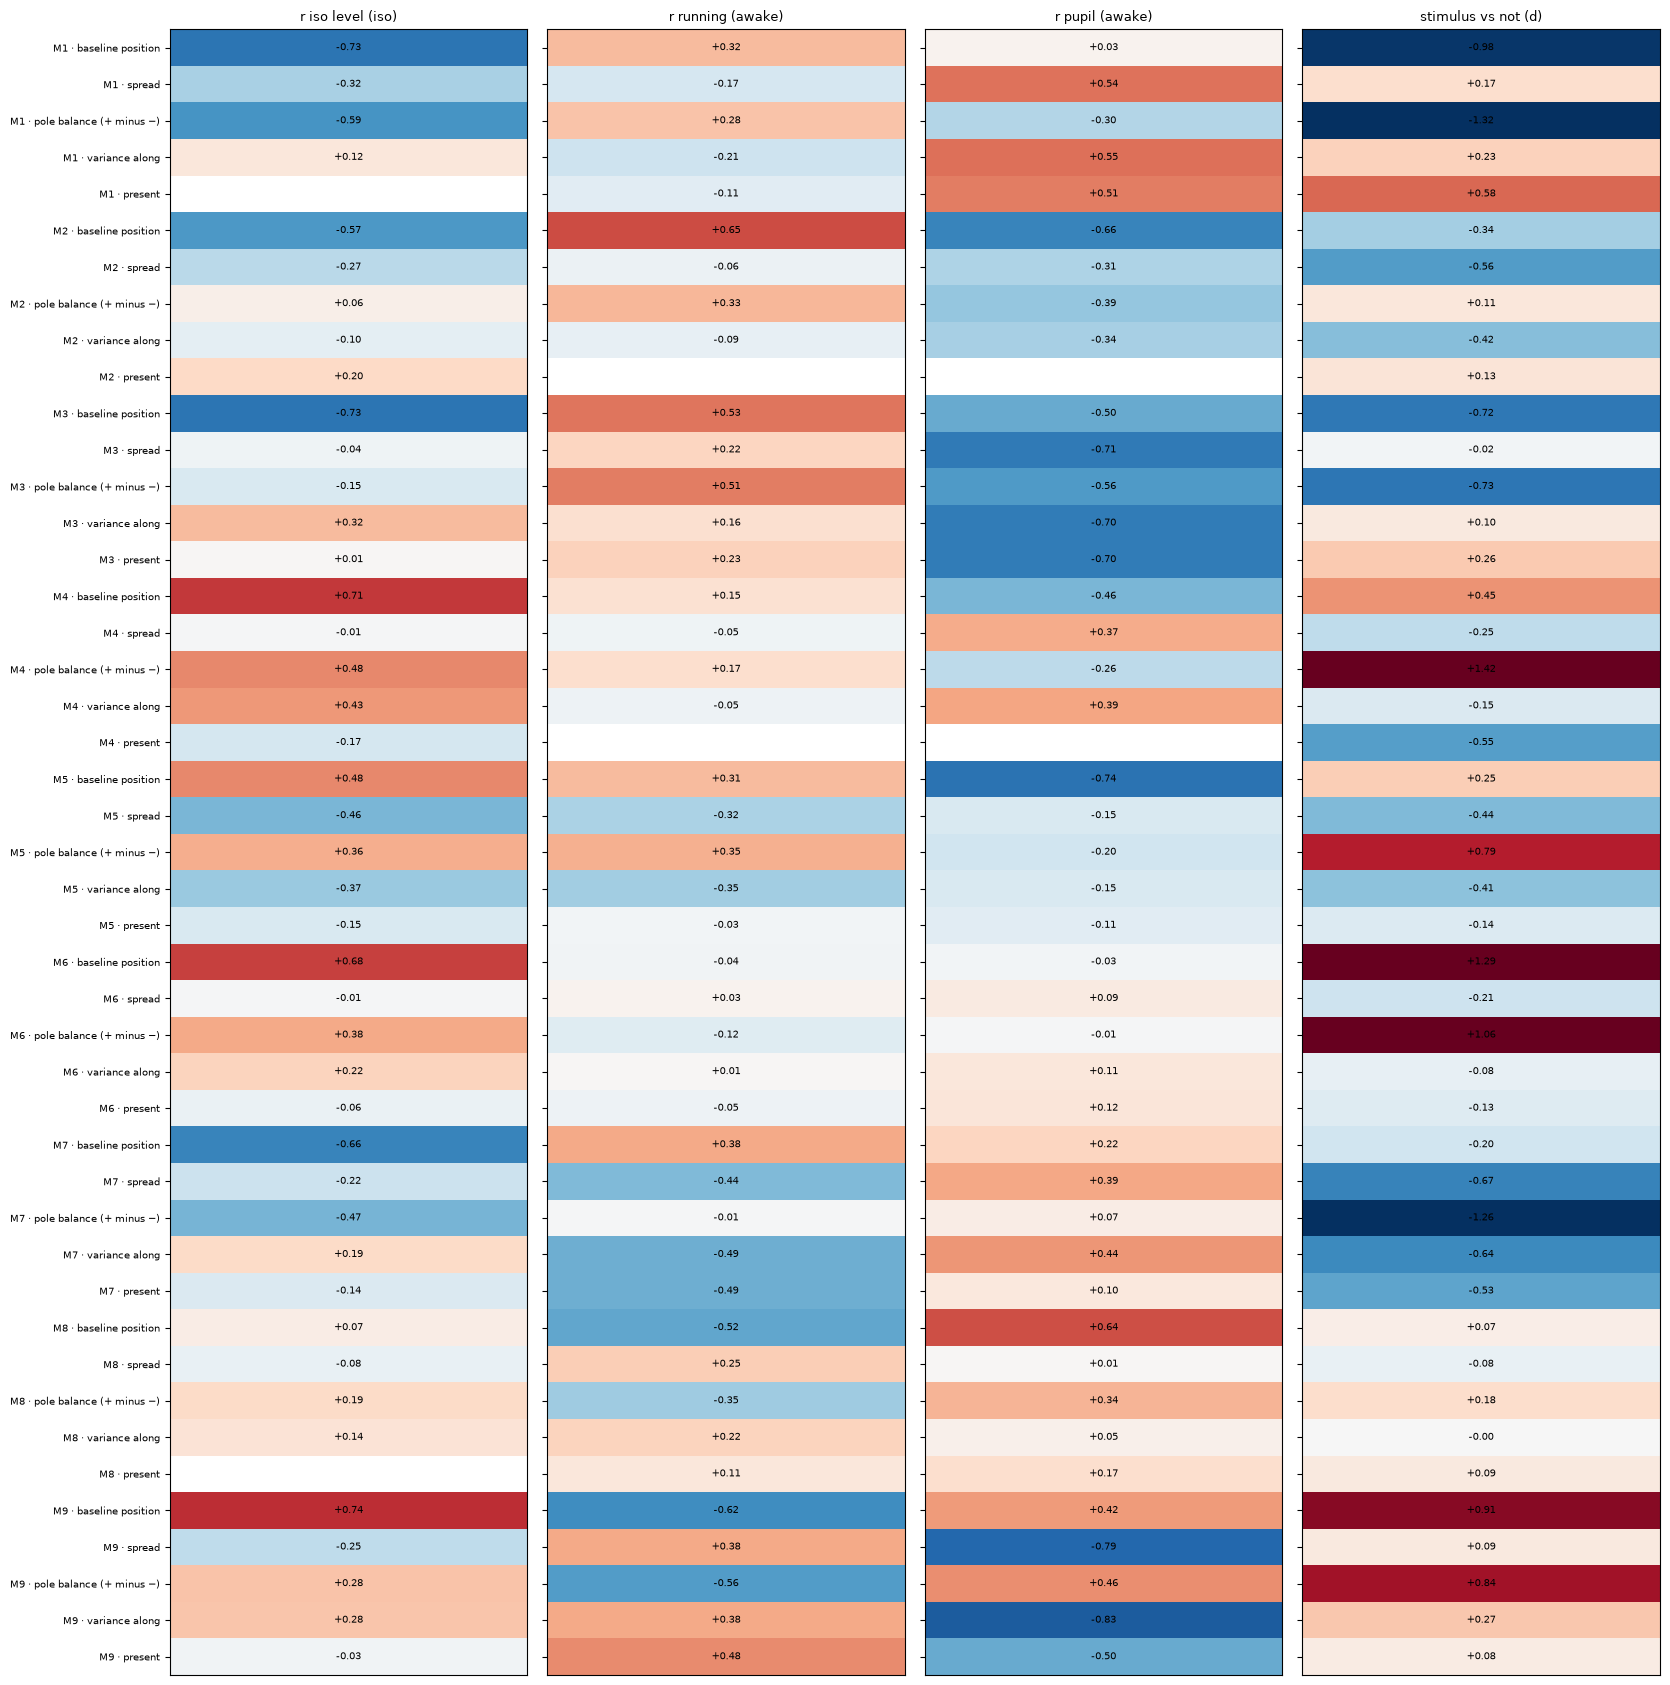

In [6]:
cw_ = res.centres
iso_w = np.interp(cw_, info.iso_t, info.iso_level)
run_w = np.array([np.nanmean(run[(run_t >= c - 150) & (run_t < c + 150)]) for c in cw_])
okp = np.isfinite(pupil)
pup_w = np.array([np.nanmean(pupil[okp][(pupil_t[okp] >= c - 150) & (pupil_t[okp] < c + 150)]) for c in cw_])
in_block = lambda c, blocks: any(a <= c < b for _, a, b in blocks)
stim_w = np.array([in_block(c, info.stim_blocks) or in_block(c, info.visual_blocks) for c in cw_])
awake_w = cw_ < info.iso_on - 30
iso_win = cw_ > info.induction_end
quant = {"baseline position": "base_pos", "spread": "sd_expr", "pole balance (+ minus −)": None, "variance along": "var_along",
         "present": "present"}
rows = []
for mi in range(K):
    w = ws[ws.motif == mi].set_index("window").reindex(range(len(cw_)))
    for lab, col in quant.items():
        x = (w.p_plus - w.p_minus) if col is None else w[col].astype(float)
        x = x.to_numpy()
        def r(sel, y):
            k = sel & np.isfinite(x) & np.isfinite(y)
            return np.corrcoef(x[k], y[k])[0, 1] if k.sum() > 5 and np.std(x[k]) > 0 else np.nan
        s1, s0 = x[stim_w & np.isfinite(x)], x[~stim_w & np.isfinite(x)]
        rows.append({"motif": f"M{mi + 1}", "quantity": lab, "r iso level (iso)": r(iso_win, iso_w),
                     "r running (awake)": r(awake_w, run_w), "r pupil (awake)": r(awake_w, pup_w),
                     "stimulus vs not (d)": (s1.mean() - s0.mean()) / np.sqrt((s1.var() + s0.var()) / 2) if s1.size and s0.size else np.nan})
assoc = pd.DataFrame(rows)
assoc.to_csv(OUT / "4_associations.csv", index=False)
cols = ["r iso level (iso)", "r running (awake)", "r pupil (awake)", "stimulus vs not (d)"]
fig, axes = plt.subplots(1, len(cols), figsize=(4.2 * len(cols), 0.35 * len(assoc) + 1.2), sharey=True)
for ax, c in zip(axes, cols):
    v = assoc[c].to_numpy()[:, None]
    ax.imshow(v, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i, x in enumerate(v[:, 0]):
        ax.text(0, i, "" if np.isnan(x) else f"{x:+.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks([]); ax.set_title(c, fontsize=9)
axes[0].set_yticks(range(len(assoc)), [f"{a} · {b}" for a, b in zip(assoc.motif, assoc.quantity)], fontsize=7)
fig.tight_layout(); save(fig, "4_associations"); plt.show()

## 5. All motifs at a glance

Baseline position and spread of every library motif over the recording (window level), with events.

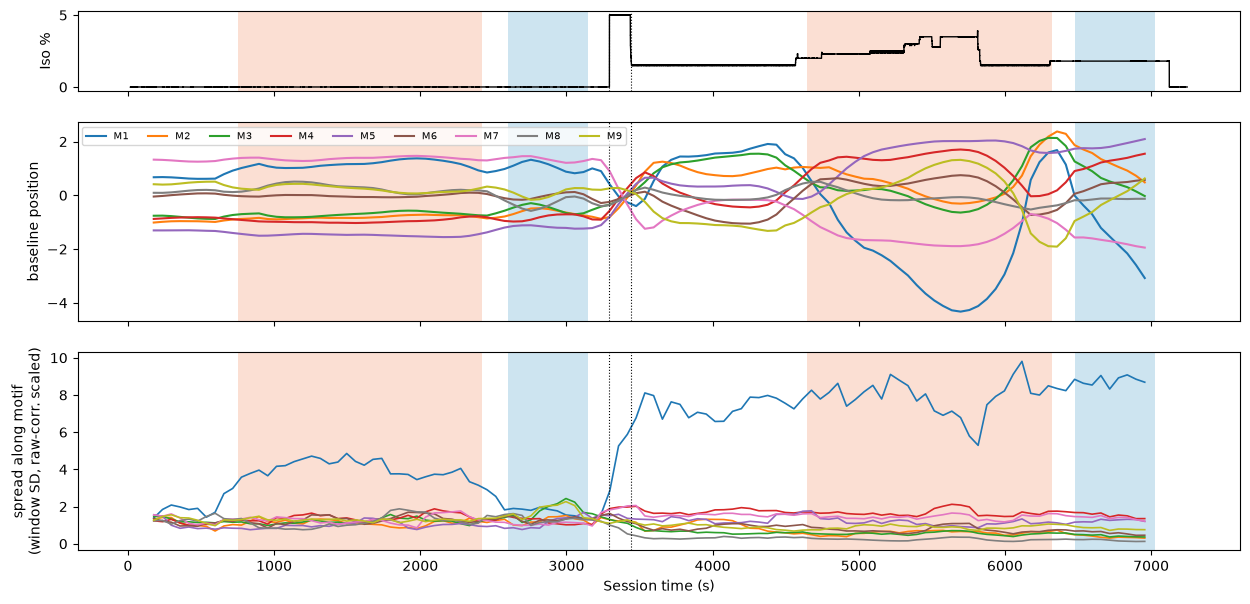

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios": [0.6, 1.5, 1.5]})
axes[0].plot(info.iso_t, info.iso_level, "k", lw=1); axes[0].set_ylabel("Iso %")
for mi in range(K):
    w = ws[ws.motif == mi].sort_values("centre")
    axes[1].plot(w.centre, w.base_pos, color=MCOL(mi), lw=1.5, label=f"M{mi + 1}")
    axes[2].plot(w.centre, w.sd_expr * np.sqrt(w.var_along), color=MCOL(mi), lw=1.2)
axes[1].set_ylabel("baseline position"); axes[1].legend(fontsize=7, ncol=K)
axes[2].set_ylabel("spread along motif\n(window SD, raw-corr. scaled)"); axes[2].set_xlabel("Session time (s)")
for a in axes: events(a)
save(fig, "5_all_motifs"); plt.show()

## 6. Scaling: the same on four signals

Deep prelimbic (PL5), secondary motor layer 5 (MOs5), hippocampal CA3 LFP, and frontal EEG channel 13, run in
parallel with `track_many`, saved per signal under `data/processed/motif_tracking/<mouse>/`. Comparison: library sizes,
how similar the motifs are across signals, and the baseline of each signal's most persistent motif.

In [8]:
io, nwb = sd.open_nwb(NWB)
sigs = {s["key"]: s["source"] for s in list_signals(nwb)}
io.close()
want = [k for k in ("lfp_PL5", "lfp_MOs5", "lfp_CA3", "eeg13") if k in sigs]
multi = mt.track_many(NWB, [(k, sigs[k]) for k in want], cfg, out_dir=STORE)
pd.DataFrame([{"signal": k, "library": len(multi[k].library), "broadband motifs": sum(m.broadband for m in multi[k].library),
               "longest-lived motif (windows)": max((m.life for m in multi[k].library), default=0),
               "candidates": len(multi[k].candidates)} for k in want]).set_index("signal")

,library,broadband motifs,longest-lived motif (windows),candidates
signal,,,,
lfp_PL5,9,1,89,191
lfp_MOs5,7,1,90,179
lfp_CA3,6,1,69,171
eeg13,6,1,77,148


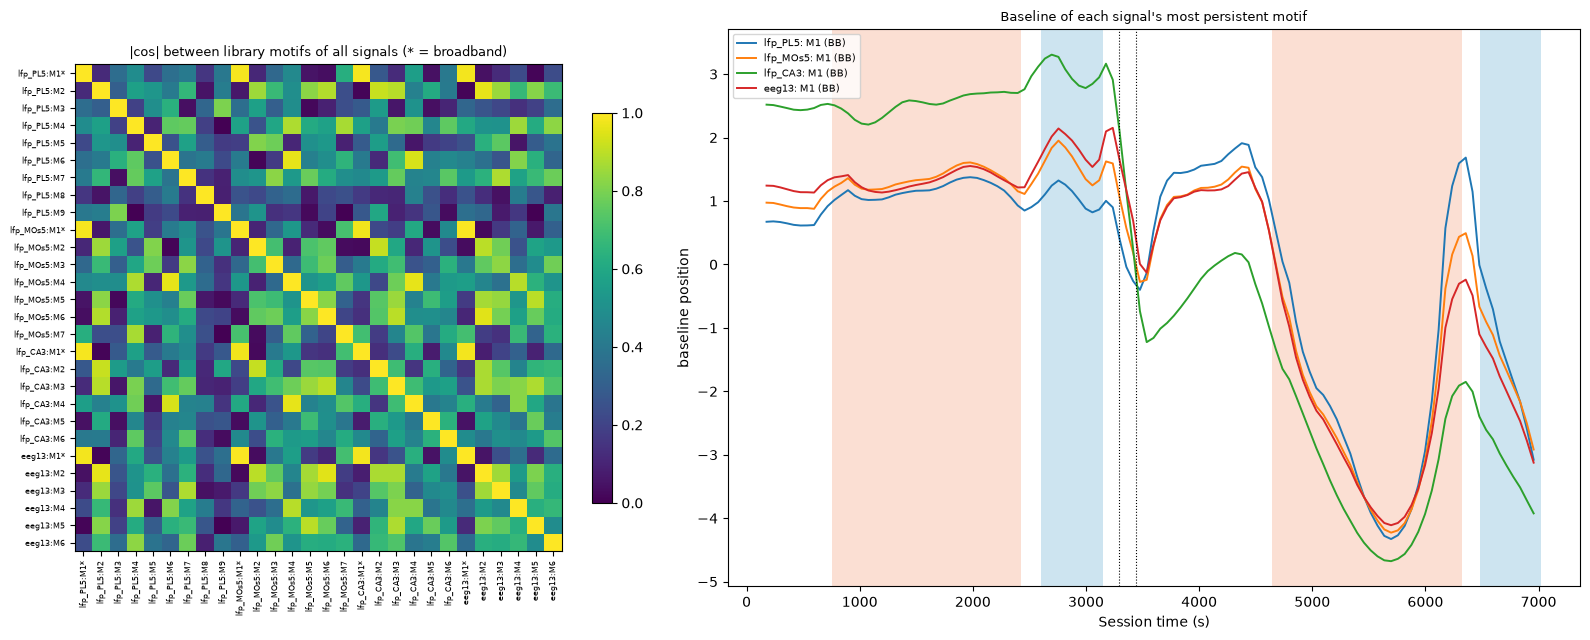

In [9]:
allm = [(k, i, m) for k in want for i, m in enumerate(multi[k].library)]
T = np.array([m.template for _, _, m in allm])
S = np.abs(T @ T.T)
labels = [f"{k}:M{i + 1}{'*' if m.broadband else ''}" for k, i, m in allm]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})
im = axes[0].imshow(S, cmap="viridis", vmin=0, vmax=1)
axes[0].set_xticks(range(len(labels)), labels, rotation=90, fontsize=6); axes[0].set_yticks(range(len(labels)), labels, fontsize=6)
axes[0].set_title("|cos| between library motifs of all signals (* = broadband)", fontsize=9)
fig.colorbar(im, ax=axes[0], shrink=0.7)
for j, k in enumerate(want):
    r = multi[k]
    if not r.library: continue
    top = int(np.argmax([m.life for m in r.library]))
    w = r.window_stats[r.window_stats.motif == top].sort_values("centre")
    axes[1].plot(w.centre, w.base_pos, lw=1.4, label=f"{k}: M{top + 1}{' (BB)' if r.library[top].broadband else ''}")
axes[1].legend(fontsize=7); axes[1].set_xlabel("Session time (s)"); axes[1].set_ylabel("baseline position")
axes[1].set_title("Baseline of each signal's most persistent motif", fontsize=9); events(axes[1])
fig.tight_layout(); save(fig, "6_multi_signal"); plt.show()

## Conclusions (PL5, plus four-signal check; local-linear baseline)

**What exists over time.** Each 5-minute window has 0–3 significant candidates; 191 candidates link into 53 tracks and
a library of 9. Only **M1 (broadband-like)** lives through almost the whole recording (89 windows, present in 81%).
**M2** (low frequencies down, gamma up) lives 25 windows and appears in episodes, almost only under isoflurane. The other
7 motifs live 3–4 windows each, for example around the awake visual block, induction and the start of the isoflurane
electrical block. So the set of motifs changes over time: they appear and disappear.

**Direction.** M1 stays about 12° from its library direction (noise floor 7°). A direction re-estimated on held-out
halves explains only 3% more variance than the fixed one. M1 loses its identity only around the awake visual block and
induction. For the weak motifs, the local-angle measure isn't informative (noise floor 30–80°).

**Baseline.** M1's baseline is flat while awake and follows isoflurane dose (r = −0.73 across isoflurane windows). It
falls through the electrical block as the dose rises and rebounds after the dose drops. Several short-lived motifs'
baselines also follow dose (|r| 0.66–0.74).

**Spread and polarity.** Expression is single-humped in most windows: bimodal in 0–11% of windows, against 5% expected
by chance. M1's pole balance shifts with dose (r = −0.59), so its distribution changes shape, not just location.

**Across signals.** PL5, MOs5, CA3 and EEG channel 13 each have exactly one broadband motif as their longest-lived
(69–90 windows), and its baseline follows nearly the same dose path in all four. CA3 differs while awake and drops further
at induction.

**Compared with binned detection.** The isoflurane motif from last week's relaxed version matches M2 (|cos| 0.93), but the
awake motif found in the 1,500-s awake bin only partly matches a short-lived motif here (|cos| 0.76). 5-minute windows have
less detection power.

**Limits.** The local-linear baseline removes the old flat steps at short segments but is noisier at segment edges. One
session. Dose and electrical stimulation overlap in time.